 Compter les classes

Condition
1    1300
0      99
Name: count, dtype: int64


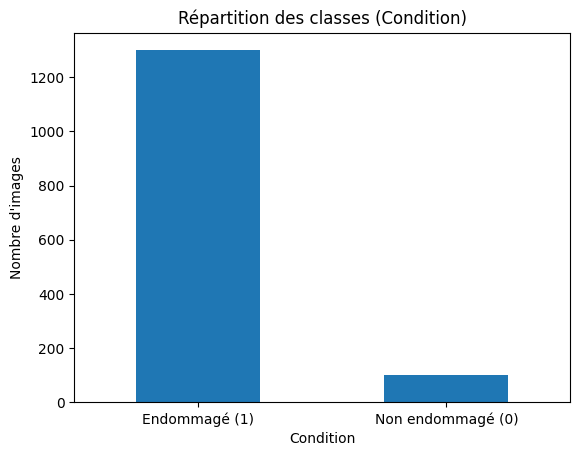

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("train.csv")              # fichier Kaggle
print(df["Condition"].value_counts())

df["Condition"].value_counts().plot(kind="bar")
plt.title("Répartition des classes (Condition)")
plt.xticks([0, 1], ["Endommagé (1)", "Non endommagé (0)"], rotation=0)
plt.ylabel("Nombre d'images")
plt.show()

Installer kagglehub

In [ ]:
!pip install kagglehub

Télécharger le dataset directement

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("infernape/fast-furious-and-insured")

print("Path to dataset files:", path)

100%|██████████| 104M/104M [00:01<00:00, 102MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/infernape/fast-furious-and-insured/versions/1


Branchez path sur la détection automatique vue précédemment

In [ ]:
import kagglehub, os, glob
import pandas as pd

path = kagglehub.dataset_download("infernape/fast-furious-and-insured")
print("Dossier du dataset :", path)
print(os.listdir(path))                       # voir ce qu'il contient

# 1. Trouver train.csv
CSV_PATH = glob.glob(f"{path}/**/train.csv", recursive=True)[0]
df = pd.read_csv(CSV_PATH)

# 2. Trouver le dossier d'images grâce à la première image du CSV
premier = df["Image_path"].iloc[0]
m = glob.glob(f"{path}/**/{os.path.basename(premier)}", recursive=True)[0]
IMG_DIR = m[:len(m) - len(premier)] if m.endswith(premier) else os.path.dirname(m) + "/"
print("IMG_DIR =", IMG_DIR)

Using Colab cache for faster access to the 'fast-furious-and-insured' dataset.
Dossier du dataset : /kaggle/input/fast-furious-and-insured
['Fast_Furious_Insured']
IMG_DIR = /kaggle/input/fast-furious-and-insured/Fast_Furious_Insured/trainImages/


Étape 1 : vérifier les données

Code 1 : ajouter la colonne chemin et vérifier que les images existent

In [ ]:
import os
import pandas as pd

AUG_DIR = "/content/aug"            # dossier modifiable (Colab) pour les images augmentées
os.makedirs(AUG_DIR, exist_ok=True)

df["chemin"] = IMG_DIR + df["Image_path"]            # chemin complet de chaque image
df["existe"] = df["chemin"].apply(os.path.exists)

print("Lignes dans train.csv :", len(df))
print("Images trouvées       :", df["existe"].sum())
print("Images manquantes     :", (~df["existe"]).sum())
print(df["Condition"].value_counts())

Lignes dans train.csv : 1399
Images trouvées       : 1399
Images manquantes     : 0
Condition
1    1300
0      99
Name: count, dtype: int64


Code 2 : images invalides, tailles et doublons

In [ ]:
import hashlib
from PIL import Image

invalides, tailles, hashes = [], [], {}
for p in df["chemin"]:
    try:
        with Image.open(p) as im:
            im.verify()                                   # fichier lisible ?
        with Image.open(p) as im:
            tailles.append(im.size)
        with open(p, "rb") as f:
            hashes.setdefault(hashlib.md5(f.read()).hexdigest(), []).append(p)
    except Exception:
        invalides.append(p)

doublons = [v for v in hashes.values() if len(v) > 1]
print("Images invalides           :", len(invalides))
print("Groupes de doublons exacts :", len(doublons))
print("Taille min :", min(tailles), "| Taille max :", max(tailles))

Images invalides           : 0
Groupes de doublons exacts : 38
Taille min : (92, 69) | Taille max : (4500, 3000)


Code 3 : afficher l’échantillon d’images

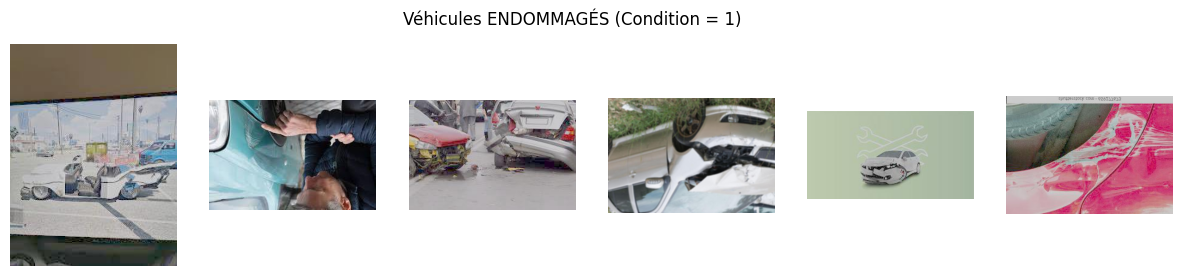

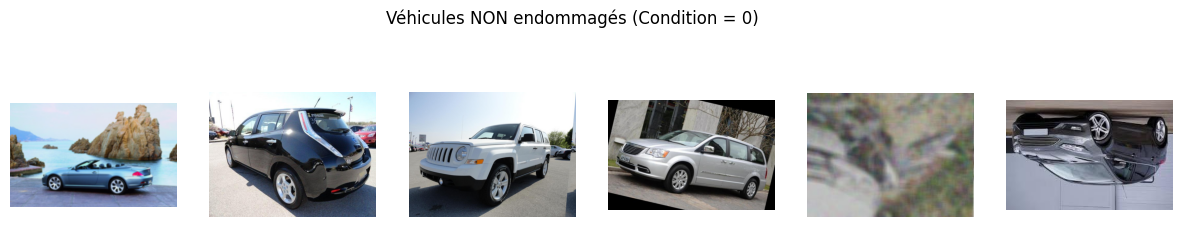

In [ ]:
def montrer(classe, n=6, titre=""):
    echantillon = df[df.Condition == classe].sample(n, random_state=42)
    plt.figure(figsize=(15, 3))
    for i, chemin in enumerate(echantillon["chemin"]):
        plt.subplot(1, n, i + 1)
        plt.imshow(Image.open(chemin)); plt.axis("off")
    plt.suptitle(titre); plt.show()

montrer(1, titre="Véhicules ENDOMMAGÉS (Condition = 1)")
montrer(0, titre="Véhicules NON endommagés (Condition = 0)")

Code 4 : analyser les doublons (à lancer d’abord)

In [ ]:
# Associer chaque image à son empreinte (hash)
def empreinte(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["hash"] = df["chemin"].apply(empreinte)
df["groupe"] = df.groupby("hash").ngroup()            # un numéro par image unique

taille_groupe = df.groupby("hash")["Image_path"].transform("count")
dup = df[taille_groupe > 1]

print("Lignes concernées par un doublon :", len(dup))
print("Répartition des classes dans ces lignes :")
print(dup["Condition"].value_counts())

# Cas grave : même image mais étiquettes différentes
conflits = dup.groupby("hash")["Condition"].nunique()
print("Groupes avec étiquettes contradictoires :", (conflits > 1).sum())

Lignes concernées par un doublon : 80
Répartition des classes dans ces lignes :
Condition
1    79
0     1
Name: count, dtype: int64
Groupes avec étiquettes contradictoires : 1


Code 5 : découper en gardant les doublons ensemble

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42

# 1) ~14 % pour le test
sgkf1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
reste_idx, test_idx = next(sgkf1.split(df, df["Condition"], groups=df["groupe"]))
reste, test_df = df.iloc[reste_idx], df.iloc[test_idx]

# 2) ~14 % du total pour la validation, pris dans le reste
sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
tr_idx, val_idx = next(sgkf2.split(reste, reste["Condition"], groups=reste["groupe"]))
train_df, val_df = reste.iloc[tr_idx], reste.iloc[val_idx]

for nom, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{nom:5s} {len(d):4d} lignes ({len(d)/len(df):.0%}) |",
          d["Condition"].value_counts().to_dict())

train  999 lignes (72%) | {1: 938, 0: 61}
val    199 lignes (14%) | {1: 175, 0: 24}
test   199 lignes (14%) | {1: 186, 0: 13}


Code 6 : vérifier l’absence de fuite et sauvegarder

In [ ]:
h_train, h_val, h_test = set(train_df.hash), set(val_df.hash), set(test_df.hash)
print("Images communes train/val  :", len(h_train & h_val))     # doit être 0
print("Images communes train/test :", len(h_train & h_test))    # doit être 0
print("Images communes val/test   :", len(h_val & h_test))      # doit être 0

train_df.to_csv("split_train.csv", index=False)
val_df.to_csv("split_val.csv", index=False)
test_df.to_csv("split_test.csv", index=False)

Images communes train/val  : 0
Images communes train/test : 0
Images communes val/test   : 0


Code 7 : regarder ce groupe

           Image_path  Condition
421   img_4514696.jpg          0
1213  img_7766946.jpg          1


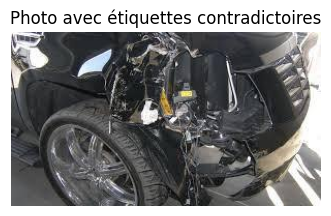

In [ ]:
conflits = df.groupby("hash")["Condition"].nunique()
hash_conflit = conflits[conflits > 1].index[0]
groupe_conflit = df[df.hash == hash_conflit]

print(groupe_conflit[["Image_path", "Condition"]])

plt.figure(figsize=(4, 3))
plt.imshow(Image.open(groupe_conflit["chemin"].iloc[0])); plt.axis("off")
plt.title("Photo avec étiquettes contradictoires"); plt.show()

Code 8 : supprimer le groupe, puis refaire le découpage

In [ ]:
n_avant = len(df)
df = df[df.hash != hash_conflit].reset_index(drop=True)
print(f"Lignes supprimées : {n_avant - len(df)} | Lignes restantes : {len(df)}")
print(df["Condition"].value_counts())

Lignes supprimées : 2 | Lignes restantes : 1397
Condition
1    1299
0      98
Name: count, dtype: int64


Étape 2 : générer les images augmentées (train uniquement)

Code 9 : la fonction de transformation

In [ ]:
import random
from PIL import Image, ImageFilter, ImageEnhance, ImageOps

def transformer(im):
    """Applique au hasard 1 à 5 petites transformations réalistes à une image."""
    ops = []
    if random.random() < 0.5:                                   # gauche <-> droite
        im = ImageOps.mirror(im); ops.append("miroir")
    if random.random() < 0.7:                                   # petite rotation
        angle = random.uniform(-15, 15)
        im = im.rotate(angle, fillcolor=(255, 255, 255)); ops.append(f"rot{angle:.0f}")
    if random.random() < 0.4:                                   # flou léger
        im = im.filter(ImageFilter.GaussianBlur(random.uniform(0.5, 1.5))); ops.append("flou")
    if random.random() < 0.6:                                   # luminosité
        im = ImageEnhance.Brightness(im).enhance(random.uniform(0.8, 1.2)); ops.append("lumiere")
    if random.random() < 0.4:                                   # zoom léger
        w, h = im.size; f = random.uniform(0.85, 0.95)
        l = random.randint(0, int(w * (1 - f))); t = random.randint(0, int(h * (1 - f)))
        im = im.crop((l, t, l + int(w * f), t + int(h * f))).resize((w, h)); ops.append("zoom")
    return im, "+".join(ops) or "original"

Code 10 : créer les images et le tableau complet

In [ ]:
import os
import pandas as pd

random.seed(42)
os.makedirs(AUG_DIR, exist_ok=True)

train_df = pd.read_csv("split_train.csv")
val_df   = pd.read_csv("split_val.csv")
test_df  = pd.read_csv("split_test.csv")

# Marquer les vraies lignes (val et test restent INCHANGÉS)
for d in (train_df, val_df, test_df):
    d["is_augmented"] = False
    d["origine"] = ""
    d["transfo"] = ""

n_pos = (train_df.Condition == 1).sum()
negatifs = train_df[train_df.Condition == 0]
CIBLE = n_pos            # objectif : autant de 0 que de 1 (on peut tester 400 plus tard)

nouvelles, i = [], 0
while len(negatifs) + len(nouvelles) < CIBLE:
    ligne = negatifs.iloc[i % len(negatifs)]
    with Image.open(ligne["chemin"]) as im:
        nouvelle, ops = transformer(im.convert("RGB"))
    nom = f"aug_{i}.jpg"
    nouvelle.save(os.path.join(AUG_DIR, nom))

    nl = ligne.to_dict()                          # COPIE TOUTES LES COLONNES (Amount, Cost_of_vehicle...)
    nl.update({"Image_path": "aug/" + nom,
               "chemin": os.path.join(AUG_DIR, nom),   # chemin complet : le CNN lira cette colonne
               "is_augmented": True,
               "origine": ligne["Image_path"],
               "transfo": ops})
    nouvelles.append(nl)
    i += 1

train_cnn = pd.concat([train_df, pd.DataFrame(nouvelles)], ignore_index=True)
train_cnn.to_csv("split_train_cnn.csv", index=False)
print(train_cnn["Condition"].value_counts())
print("Images augmentées créées :", len(nouvelles))

Condition
0    938
1    938
Name: count, dtype: int64
Images augmentées créées : 877


Code 11 : vérifier que tout est correct

In [ ]:
# 1. Colonnes conservées
print("Colonnes :", list(train_cnn.columns))

# 2. Pas de valeurs manquantes créées par l'augmentation
cols_utiles = [c for c in ["Image_path", "Condition", "Amount", "Cost_of_vehicle"] if c in train_cnn.columns]
print(train_cnn.groupby("is_augmented")[cols_utiles].apply(lambda g: g.isna().sum()))

# 3. Aucune copie ne vient du val ou du test
origines = set(train_cnn[train_cnn.is_augmented]["origine"])
print("Origines dans val  :", len(origines & set(val_df.Image_path)))    # doit être 0
print("Origines dans test :", len(origines & set(test_df.Image_path)))   # doit être 0

# 4. Toutes les images existent
absentes = [p for p in train_cnn["chemin"] if not os.path.exists(p)]
print("Images introuvables :", len(absentes))                            # doit être 0

Colonnes : ['Image_path', 'Insurance_company', 'Cost_of_vehicle', 'Min_coverage', 'Expiry_date', 'Max_coverage', 'Condition', 'Amount', 'chemin', 'existe', 'hash', 'groupe', 'is_augmented', 'origine', 'transfo']
              Image_path  Condition  Amount  Cost_of_vehicle
is_augmented                                                
False                  0          0       9               67
True                   0          0       0                0
Origines dans val  : 0
Origines dans test : 0
Images introuvables : 0


Étape 3 : voir le résultat

Code 12 : graphique avant / après

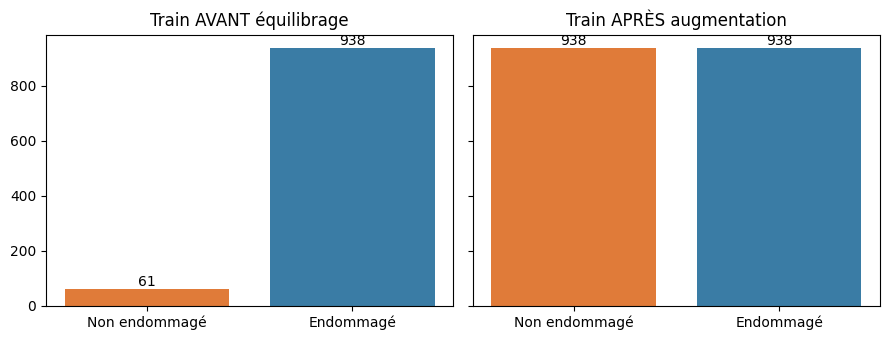

In [ ]:
import matplotlib.pyplot as plt

avant = train_df["Condition"].value_counts().sort_index()
apres = train_cnn["Condition"].value_counts().sort_index()

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for a, data, titre in [(ax[0], avant, "Train AVANT équilibrage"),
                       (ax[1], apres, "Train APRÈS augmentation")]:
    a.bar(["Non endommagé", "Endommagé"], data.values, color=["#e07b39", "#3a7ca5"])
    a.set_title(titre)
    for k, v in enumerate(data.values):
        a.text(k, v, str(v), ha="center", va="bottom")
plt.tight_layout(); plt.show()

Code 13 : une photo originale et ses versions transformées

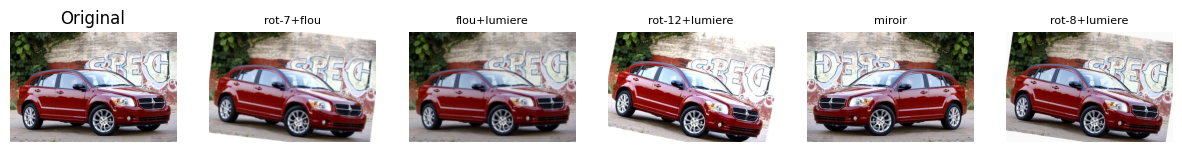

In [ ]:
orig = negatifs.iloc[0]
variantes = train_cnn[(train_cnn.is_augmented) & (train_cnn.origine == orig["Image_path"])].head(5)

plt.figure(figsize=(15, 3))
plt.subplot(1, 6, 1); plt.imshow(Image.open(orig["chemin"])); plt.title("Original"); plt.axis("off")
for k, (_, r) in enumerate(variantes.iterrows()):
    plt.subplot(1, 6, k + 2)
    plt.imshow(Image.open(r["chemin"])); plt.title(r["transfo"], fontsize=8); plt.axis("off")
plt.show()

Vérification de Amount

In [ ]:
print(df.groupby("Condition")["Amount"].describe())
print(df[df.Condition == 0]["Amount"].value_counts().head())

            count         mean          std    min     25%     50%      75%  \
Condition                                                                     
0            98.0     0.000000     0.000000    0.0     0.0     0.0     0.00   
1          1288.0  4432.556677  3049.408568 -999.0  2691.0  4351.0  6176.75   

               max  
Condition           
0              0.0  
1          59844.0  
Amount
0.0    98
Name: count, dtype: int64


Les effectifs du découpage

In [ ]:
import pandas as pd

lignes = []
for nom, d in [("Train (sans copies)", train_df[~train_df.is_augmented]),
               ("Train (avec copies)", train_cnn),
               ("Validation", val_df),
               ("Test", test_df)]:
    vc = d["Condition"].value_counts()
    lignes.append({"Ensemble": nom,
                   "Total": len(d),
                   "Endommagé (1)": vc.get(1, 0),
                   "Non endommagé (0)": vc.get(0, 0),
                   "% non endommagé": round(100 * vc.get(0, 0) / len(d), 1)})

tableau_effectifs = pd.DataFrame(lignes)
print(tableau_effectifs.to_string(index=False))
tableau_effectifs.to_csv("tableau_effectifs.csv", index=False)

           Ensemble  Total  Endommagé (1)  Non endommagé (0)  % non endommagé
Train (sans copies)    999            938                 61              6.1
Train (avec copies)   1876            938                938             50.0
         Validation    199            175                 24             12.1
               Test    199            186                 13              6.5


Cellule A : monter le Drive et restaurer les images augmentées,
on trouve aug.zip, les CSV et le futur modèle.

In [ ]:
import os, shutil
from google.colab import drive

# 1) vérifier que les images existent
print(len(os.listdir("/content/aug")), "images augmentées dans /content/aug")

# 2) monter le Drive
drive.mount('/content/drive')

# 3) créer le dossier et y copier les images (zip) et les CSV
SAVE_DIR = "/content/drive/MyDrive/projet_auto_cnn"
os.makedirs(SAVE_DIR, exist_ok=True)

shutil.make_archive(f"{SAVE_DIR}/aug", "zip", "/content/aug")
for f in ["split_train_cnn.csv", "split_val.csv", "split_test.csv"]:
    shutil.copy(f, SAVE_DIR)

print(os.listdir(SAVE_DIR))

877 images augmentées dans /content/aug
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['aug.zip', 'split_train_cnn.csv', 'split_val.csv', 'split_test.csv']


Cellule de restauration (dézipper) : elle ne sert que dans une nouvelle session, quand /content/aug est vide. Dans Deep.ipynb, les images viennent d’être créées, donc elle n’a pas sa place là. Elle doit aller dans le notebook CNN, tout au début. Si vous la gardez dans Deep.ipynb, elle réécrase simplement les mêmes fichiers.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = "/content/drive/MyDrive/projet_auto_cnn"

# dézipper les images augmentées dans /content/aug
!mkdir -p /content/aug
!unzip -q -o {SAVE_DIR}/aug.zip -d /content/aug

import os
print(len(os.listdir("/content/aug")), "images augmentées restaurées")

Mounted at /content/drive
unzip:  cannot find or open /content/drive/MyDrive/projet_auto_cnn/aug.zip, /content/drive/MyDrive/projet_auto_cnn/aug.zip.zip or /content/drive/MyDrive/projet_auto_cnn/aug.zip.ZIP.
877 images augmentées restaurées
